# 1. Decision Trees as Interpretable Models

## (a)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import (DecisionTreeClassifier, plot_tree, export_text)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import (LinearRegression, RidgeCV, LassoCV)

from sklearn.decomposition import PCA
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

In [2]:
diagnosis_columns = [
    "Temperature",
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pain",
    "Burning_Urethra",
    "Bladder_Inflammation",
    "Nephritis"
]

diagnosis_df = pd.read_csv(
    "diagnosis.data",
    sep="\t",
    header=None,
    names=diagnosis_columns,
    encoding="utf-16",
    decimal=","
)

diagnosis_df.head()

print("Dataset shape:", diagnosis_df.shape)
print("\nMissing values:")
print(diagnosis_df.isnull().sum())

diagnosis_df.info()

Dataset shape: (120, 8)

Missing values:
Temperature             0
Nausea                  0
Lumbar_Pain             0
Urine_Pushing           0
Micturition_Pain        0
Burning_Urethra         0
Bladder_Inflammation    0
Nephritis               0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           120 non-null    float64
 1   Nausea                120 non-null    str    
 2   Lumbar_Pain           120 non-null    str    
 3   Urine_Pushing         120 non-null    str    
 4   Micturition_Pain      120 non-null    str    
 5   Burning_Urethra       120 non-null    str    
 6   Bladder_Inflammation  120 non-null    str    
 7   Nephritis             120 non-null    str    
dtypes: float64(1), str(7)
memory usage: 9.7 KB


In [3]:
feature_columns = [
    "Temperature",
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pain",
    "Burning_Urethra"
]

X = diagnosis_df[feature_columns].copy()

binary_columns = [
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pain",
    "Burning_Urethra"
]

X[binary_columns] = X[binary_columns].replace({"no": 0, "yes": 1})

X.head()

,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pain,Burning_Urethra
0,35.5,0,1,0,0,0
1,35.9,0,0,1,1,1
2,35.9,0,1,0,0,0
3,36.0,0,0,1,1,1
4,36.0,0,1,0,0,0


In [4]:
label_mapping = {
    ("no", "no"): "Neither",
    ("yes", "no"): "Bladder_Inflammation",
    ("no", "yes"): "Nephritis",
    ("yes", "yes"): "Both"
}

y = diagnosis_df[["Bladder_Inflammation", "Nephritis"]].apply(
    lambda row: label_mapping[(row["Bladder_Inflammation"], row["Nephritis"])],
    axis=1
)

y.head()

print("Encoded feature data:")
display(X.head())

print("\nLabel distribution:")
print(y.value_counts())

Encoded feature data:


,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pain,Burning_Urethra
0,35.5,0,1,0,0,0
1,35.9,0,0,1,1,1
2,35.9,0,1,0,0,0
3,36.0,0,0,1,1,1
4,36.0,0,1,0,0,0



Label distribution:
Bladder_Inflammation    40
Nephritis               31
Neither                 30
Both                    19
Name: count, dtype: int64


In [5]:
label_order = ["Neither", "Bladder_Inflammation", "Nephritis", "Both"]

print(y.value_counts().reindex(label_order, fill_value=0))

Neither                 30
Bladder_Inflammation    40
Nephritis               31
Both                    19
Name: count, dtype: int64


## (b)

In [6]:
full_tree = DecisionTreeClassifier(criterion="gini", random_state=42)

full_tree.fit(X, y)

print("Training accuracy:", full_tree.score(X, y))
print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())

Training accuracy: 1.0
Tree depth: 4
Number of leaves: 6


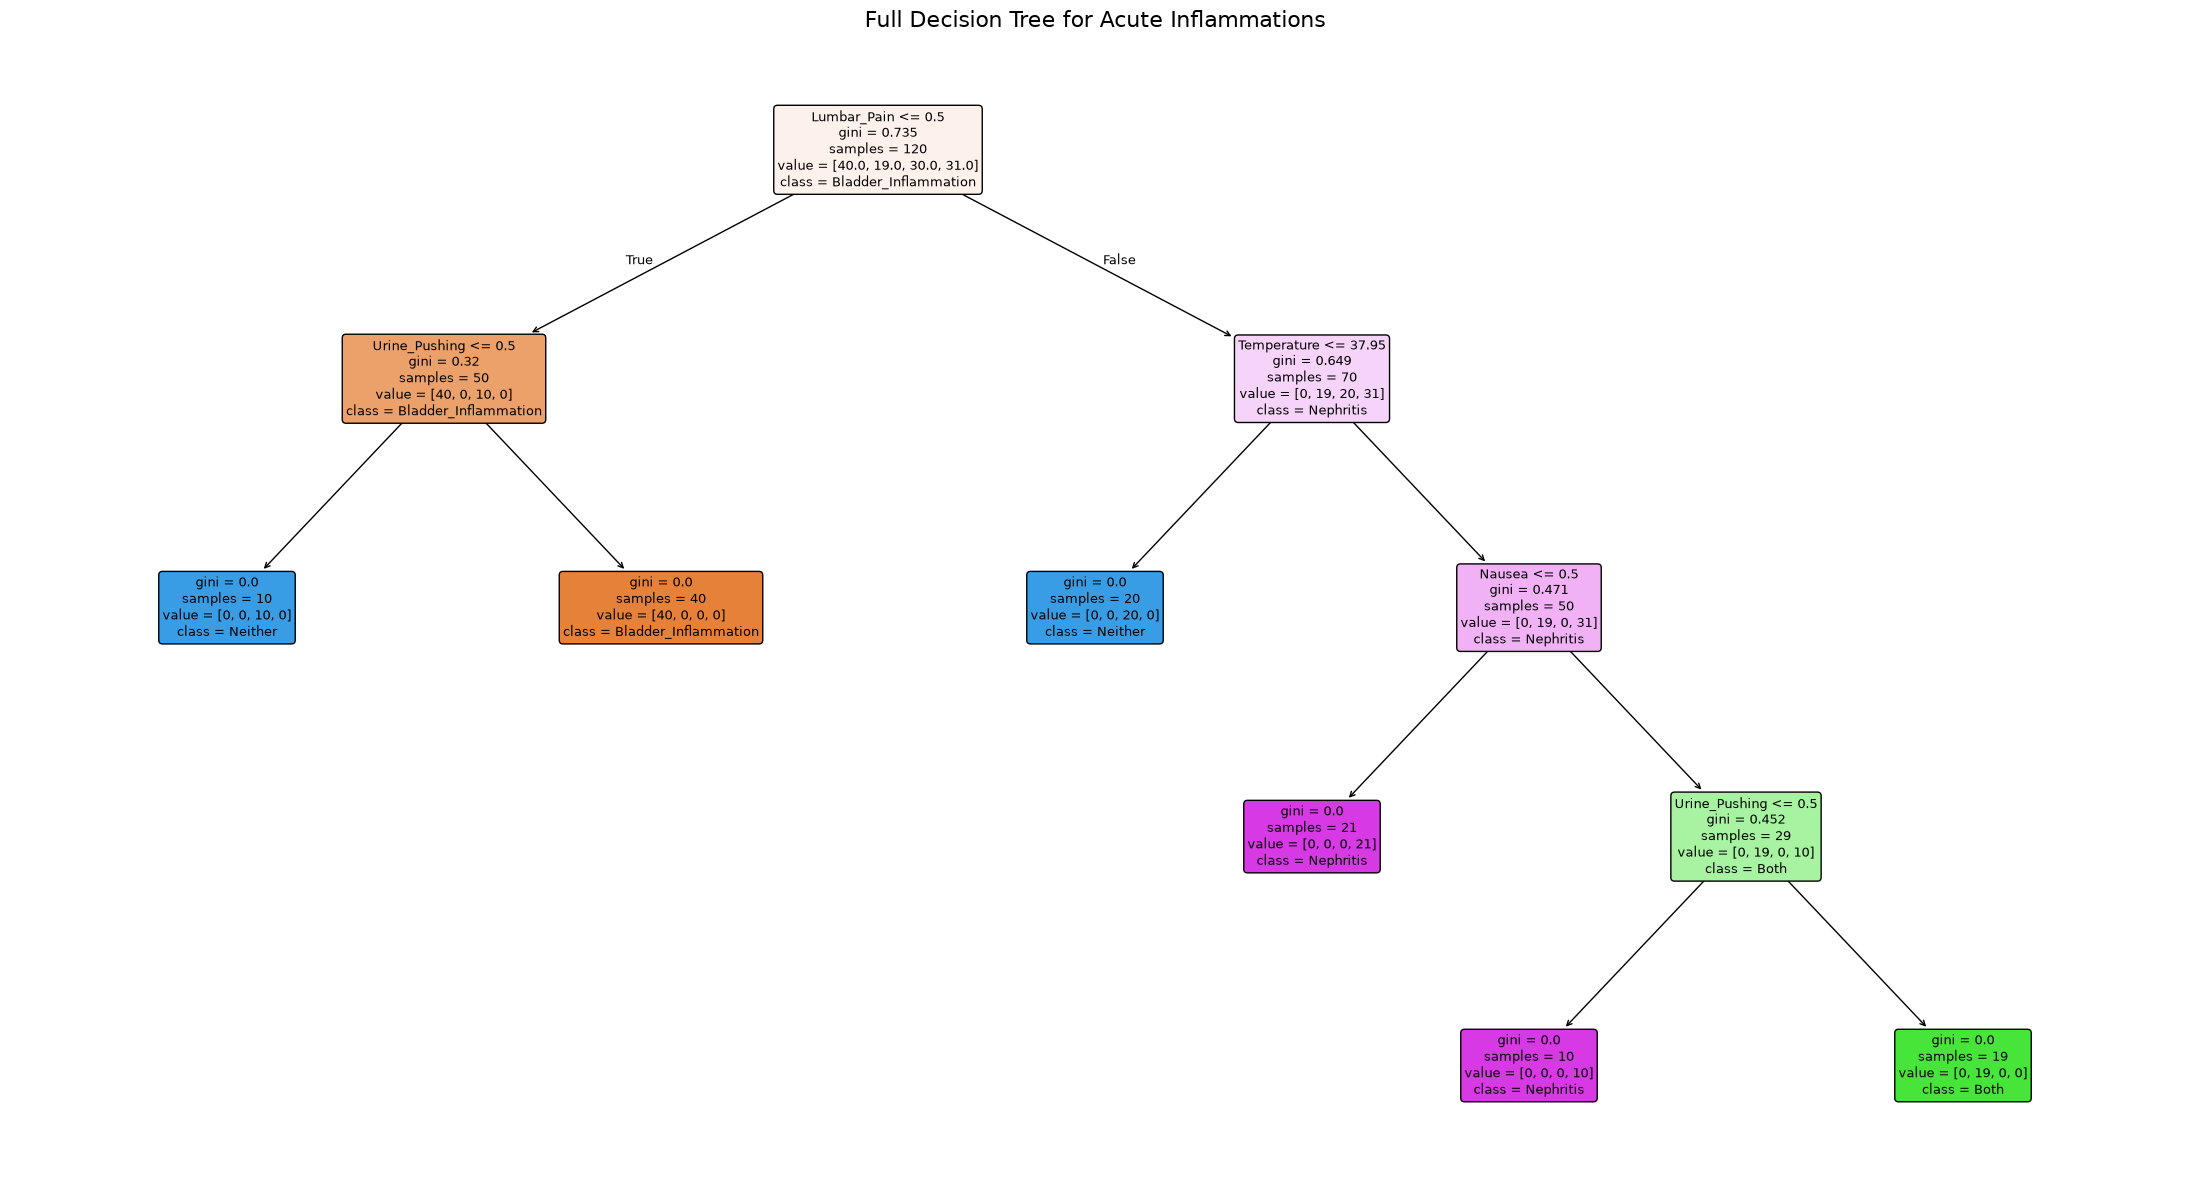

In [7]:
plt.figure(figsize=(22, 12))

plot_tree(
    full_tree,
    feature_names=X.columns,
    class_names=full_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Full Decision Tree for Acute Inflammations", fontsize=16)
plt.tight_layout()
plt.show()

## (c)

In [8]:
def extract_readable_rules(model, feature_names, binary_features):
    tree = model.tree_
    rules = []

    def format_condition(feature, threshold, direction):
        if feature in binary_features and np.isclose(threshold, 0.5):
            if direction == "left":
                return f"{feature} = no"
            else:
                return f"{feature} = yes"

        if direction == "left":
            return f"{feature} <= {threshold:.2f}"
        else:
            return f"{feature} > {threshold:.2f}"

    def traverse(node, conditions):
        if tree.feature[node] != -2:
            feature = feature_names[tree.feature[node]]
            threshold = tree.threshold[node]

            traverse(
                tree.children_left[node],
                conditions + [format_condition(feature, threshold, "left")]
            )

            traverse(
                tree.children_right[node],
                conditions + [format_condition(feature, threshold, "right")]
            )

        else:
            class_index = np.argmax(tree.value[node][0])
            predicted_class = model.classes_[class_index]
            samples = tree.n_node_samples[node]

            rule = (
                "IF "
                + " AND ".join(conditions)
                + f"\nTHEN diagnosis = {predicted_class}"
                + f" (samples = {samples})"
            )

            rules.append(rule)

    traverse(0, [])
    return rules

In [9]:
readable_rules = extract_readable_rules(full_tree, list(X.columns), binary_columns)

for number, rule in enumerate(readable_rules, start=1):
    print(f"Rule {number}:")
    print(rule)
    print("-" * 60)

Rule 1:
IF Lumbar_Pain = no AND Urine_Pushing = no
THEN diagnosis = Neither (samples = 10)
------------------------------------------------------------
Rule 2:
IF Lumbar_Pain = no AND Urine_Pushing = yes
THEN diagnosis = Bladder_Inflammation (samples = 40)
------------------------------------------------------------
Rule 3:
IF Lumbar_Pain = yes AND Temperature <= 37.95
THEN diagnosis = Neither (samples = 20)
------------------------------------------------------------
Rule 4:
IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = no
THEN diagnosis = Nephritis (samples = 21)
------------------------------------------------------------
Rule 5:
IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = no
THEN diagnosis = Nephritis (samples = 10)
------------------------------------------------------------
Rule 6:
IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = yes
THEN diagnosis = Both (samples = 19)
----------------------------

## (d)

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

pruning_path = full_tree.cost_complexity_pruning_path(X, y)

ccp_alphas = np.unique(pruning_path.ccp_alphas[:-1])

print("Candidate ccp_alpha values:")
print(ccp_alphas)

pruning_path.ccp_alphas[:-1]

Candidate ccp_alpha values:
[0.         0.09816667 0.13333333 0.182     ]


array([0.        , 0.09816667, 0.13333333, 0.182     ])

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_cv_scores = []
standard_errors = []

for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(criterion="gini", random_state=42, ccp_alpha=alpha)

    scores = cross_val_score(tree, X, y, cv=cv, scoring="accuracy")

    mean_cv_scores.append(scores.mean())
    standard_errors.append(scores.std(ddof=1) / np.sqrt(cv.get_n_splits()))

mean_cv_scores = np.array(mean_cv_scores)
standard_errors = np.array(standard_errors)

In [12]:
best_index = np.argmax(mean_cv_scores)
best_mean_score = mean_cv_scores[best_index]
best_standard_error = standard_errors[best_index]

one_se_threshold = best_mean_score - best_standard_error

eligible_indices = np.where(mean_cv_scores >= one_se_threshold)[0]

selected_index = eligible_indices[-1]
selected_alpha = ccp_alphas[selected_index]

print("Best mean CV accuracy:", best_mean_score)
print("One-standard-error threshold:", one_se_threshold)
print("Selected ccp_alpha:", selected_alpha)

Best mean CV accuracy: 0.9916666666666668
One-standard-error threshold: 0.9833333333333335
Selected ccp_alpha: 0.0


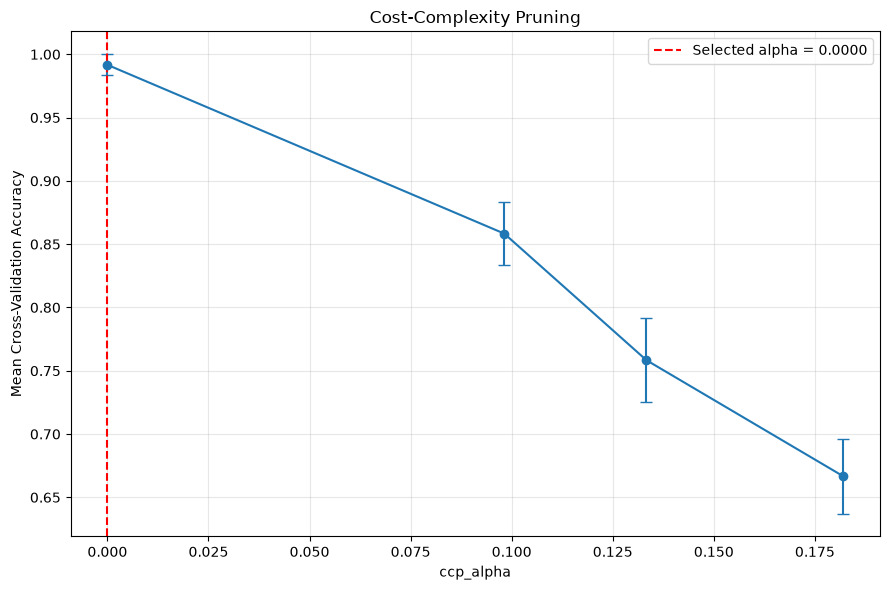

In [13]:
plt.figure(figsize=(9, 6))

plt.errorbar(ccp_alphas, mean_cv_scores, yerr=standard_errors, marker="o", capsize=4)

plt.axvline(
    selected_alpha,
    color="red",
    linestyle="--",
    label=f"Selected alpha = {selected_alpha:.4f}"
)

plt.xlabel("ccp_alpha")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Cost-Complexity Pruning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
pruned_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    ccp_alpha=selected_alpha
)

pruned_tree.fit(X, y)

print("Selected ccp_alpha:", selected_alpha)
print("Training accuracy:", pruned_tree.score(X, y))
print("Tree depth:", pruned_tree.get_depth())
print("Number of leaves:", pruned_tree.get_n_leaves())

Selected ccp_alpha: 0.0
Training accuracy: 1.0
Tree depth: 4
Number of leaves: 6


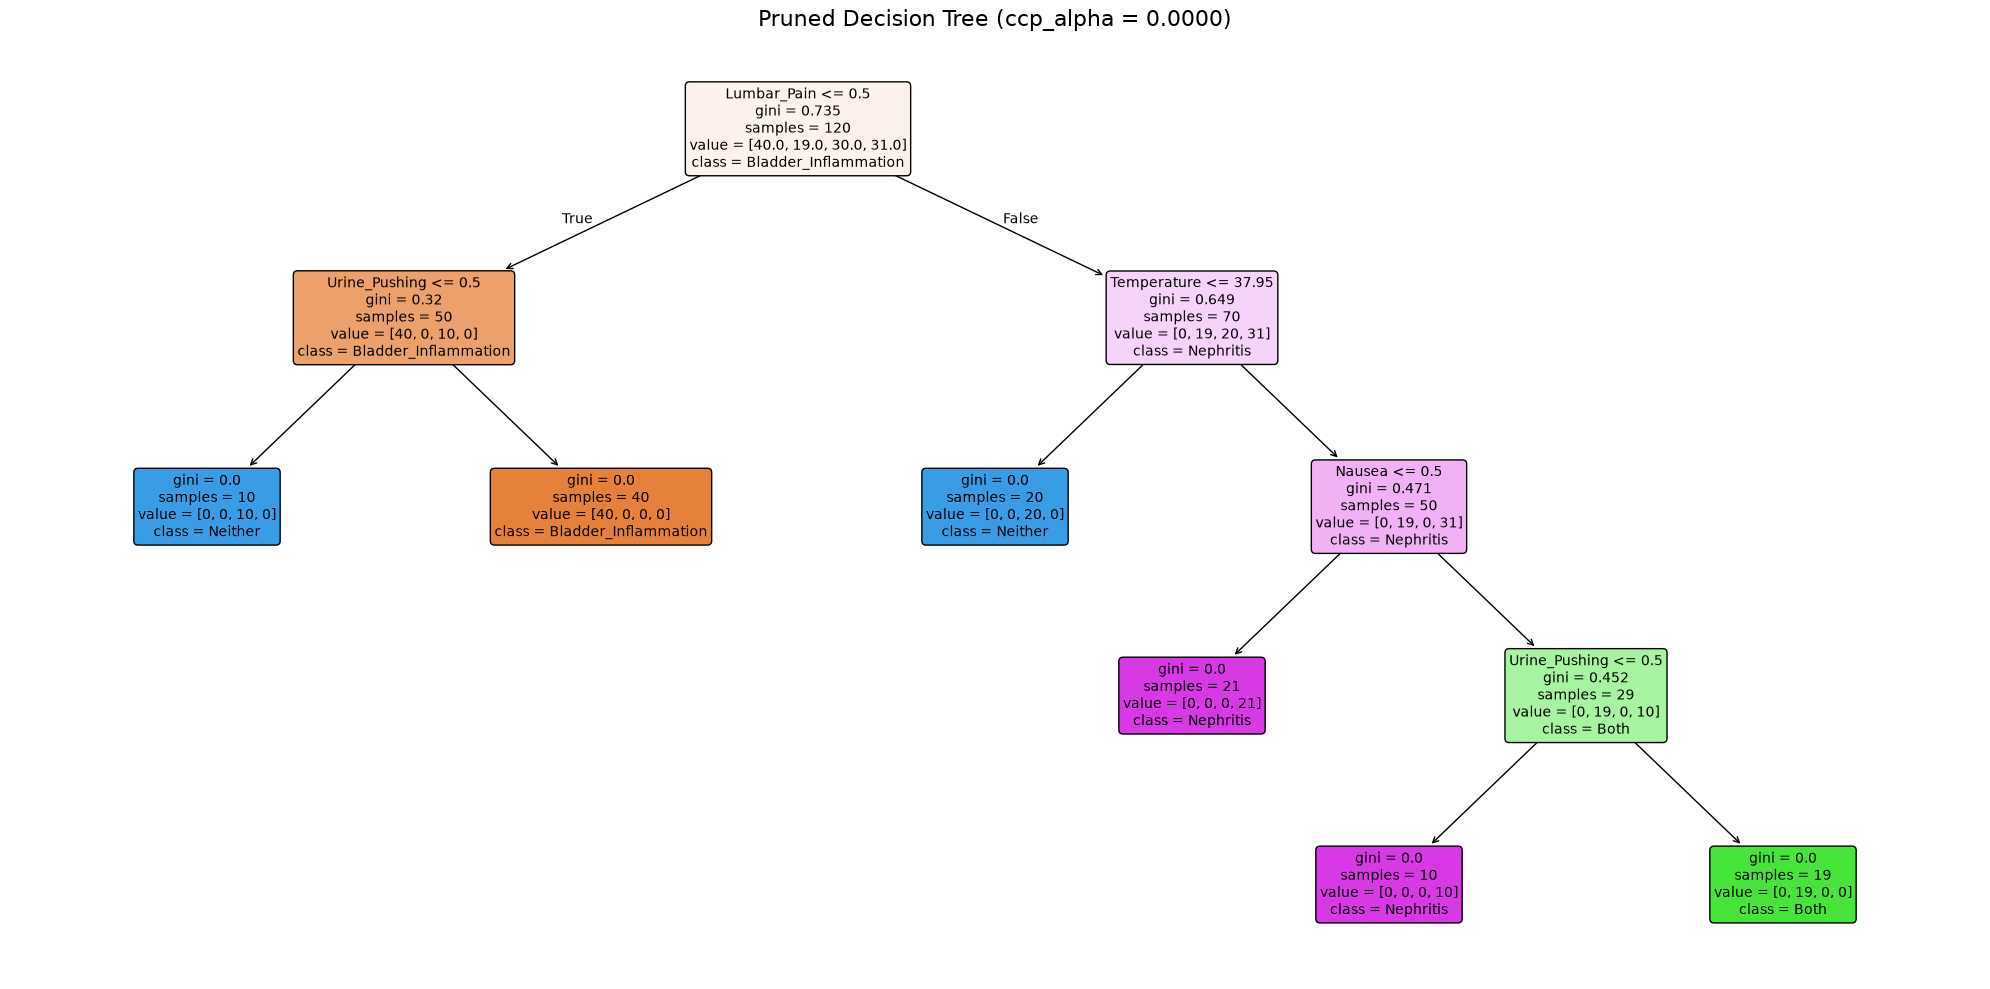

In [15]:
plt.figure(figsize=(20, 10))

plot_tree(
    pruned_tree,
    feature_names=X.columns,
    class_names=pruned_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title(f"Pruned Decision Tree (ccp_alpha = {selected_alpha:.4f})", fontsize=16)

plt.tight_layout()
plt.show()

In [16]:
pruned_rules = extract_readable_rules(pruned_tree, list(X.columns), binary_columns)

for number, rule in enumerate(pruned_rules, start=1):
    print(f"Rule {number}:")
    print(rule)
    print("-" * 60)

Rule 1:
IF Lumbar_Pain = no AND Urine_Pushing = no
THEN diagnosis = Neither (samples = 10)
------------------------------------------------------------
Rule 2:
IF Lumbar_Pain = no AND Urine_Pushing = yes
THEN diagnosis = Bladder_Inflammation (samples = 40)
------------------------------------------------------------
Rule 3:
IF Lumbar_Pain = yes AND Temperature <= 37.95
THEN diagnosis = Neither (samples = 20)
------------------------------------------------------------
Rule 4:
IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = no
THEN diagnosis = Nephritis (samples = 21)
------------------------------------------------------------
Rule 5:
IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = no
THEN diagnosis = Nephritis (samples = 10)
------------------------------------------------------------
Rule 6:
IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = yes
THEN diagnosis = Both (samples = 19)
----------------------------

# 2. The LASSO and Boosting for Regression

## (a)

In [17]:
attribute_names = []

with open("communities.names", "r", encoding="latin-1") as file:
    for line in file:
        line = line.strip()

        if line.lower().startswith("@attribute"):
            attribute_names.append(line.split()[1])

print("Number of attributes:", len(attribute_names))

Number of attributes: 128


In [18]:
crime_df = pd.read_csv(
    "communities.data",
    header=None,
    names=attribute_names,
    na_values="?"
)

crime_df.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LemasSwornFT,LemasSwFTPerPop,LemasSwFTFieldOps,LemasSwFTFieldPerPop,LemasTotalReq,LemasTotReqPerPop,PolicReqPerOffic,PolicPerPop,RacialMatchCommPol,PctPolicWhite,PctPolicBlack,PctPolicHisp,PctPolicAsian,PctPolicMinor,OfficAssgnDrugUnits,NumKindsDrugsSeiz,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,0.20,1.0,0.37,0.72,0.34,0.60,0.29,0.15,0.43,0.39,0.40,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.10,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.40,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.50,0.51,0.64,0.03,0.13,0.96,0.17,0.06,0.18,0.44,0.13,0.94,0.93,0.03,0.07,0.1,0.07,0.02,0.57,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.30,0.22,0.35,0.01,0.24,0.14,0.24,0.30,0.27,0.73,0.57,0.15,0.42,0.36,1.00,0.63,0.91,1.00,0.29,0.43,0.47,0.60,0.39,0.46,0.53,0.00,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.10,0.16,0.10,0.17,0.29,0.17,0.26,0.20,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.00,0.21,0.20,0.21,0.42,0.38,0.40,0.37,0.29,0.32,0.18,0.00,0.0,0.21,0.50,0.34,0.60,0.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.00,0.0,0.30,0.58,0.19,0.39,0.38,0.40,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.70,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.00,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.20,0.20,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.30,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.00,0.0,0.14,0.49,0.54,0.67,0.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.20,0.82,0.51,0.36,0.40,0.39,0.16,0.25,0.36,0.44,0.01,0.10,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.20,0.30,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.00,0.94,0.1

## (b)

In [19]:
non_predictive_columns = ["state", "county", "community", "communityname", "fold"]

target_column = "ViolentCrimesPerPop"

X_crime = crime_df.drop(columns=non_predictive_columns + [target_column])

y_crime = crime_df[target_column].copy()

print("Number of predictive features:", X_crime.shape[1])

Number of predictive features: 122


In [20]:
X_train = X_crime.iloc[:1495].copy()
X_test = X_crime.iloc[1495:].copy()

y_train = y_crime.iloc[:1495].copy()
y_test = y_crime.iloc[1495:].copy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1495, 122)
X_test shape: (499, 122)
y_train shape: (1495,)
y_test shape: (499,)


In [21]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [22]:
X_all_imputed = pd.DataFrame(
    imputer.transform(X_crime),
    columns=X_crime.columns,
    index=X_crime.index
)

crime_imputed_df = X_all_imputed.copy()
crime_imputed_df[target_column] = y_crime

In [23]:
print("Missing values in training set:", X_train_imputed.isnull().sum().sum())

print("Missing values in test set:", X_test_imputed.isnull().sum().sum())

print("Missing values in complete feature set:", X_all_imputed.isnull().sum().sum())

Missing values in training set: 0
Missing values in test set: 0
Missing values in complete feature set: 0


## (c)

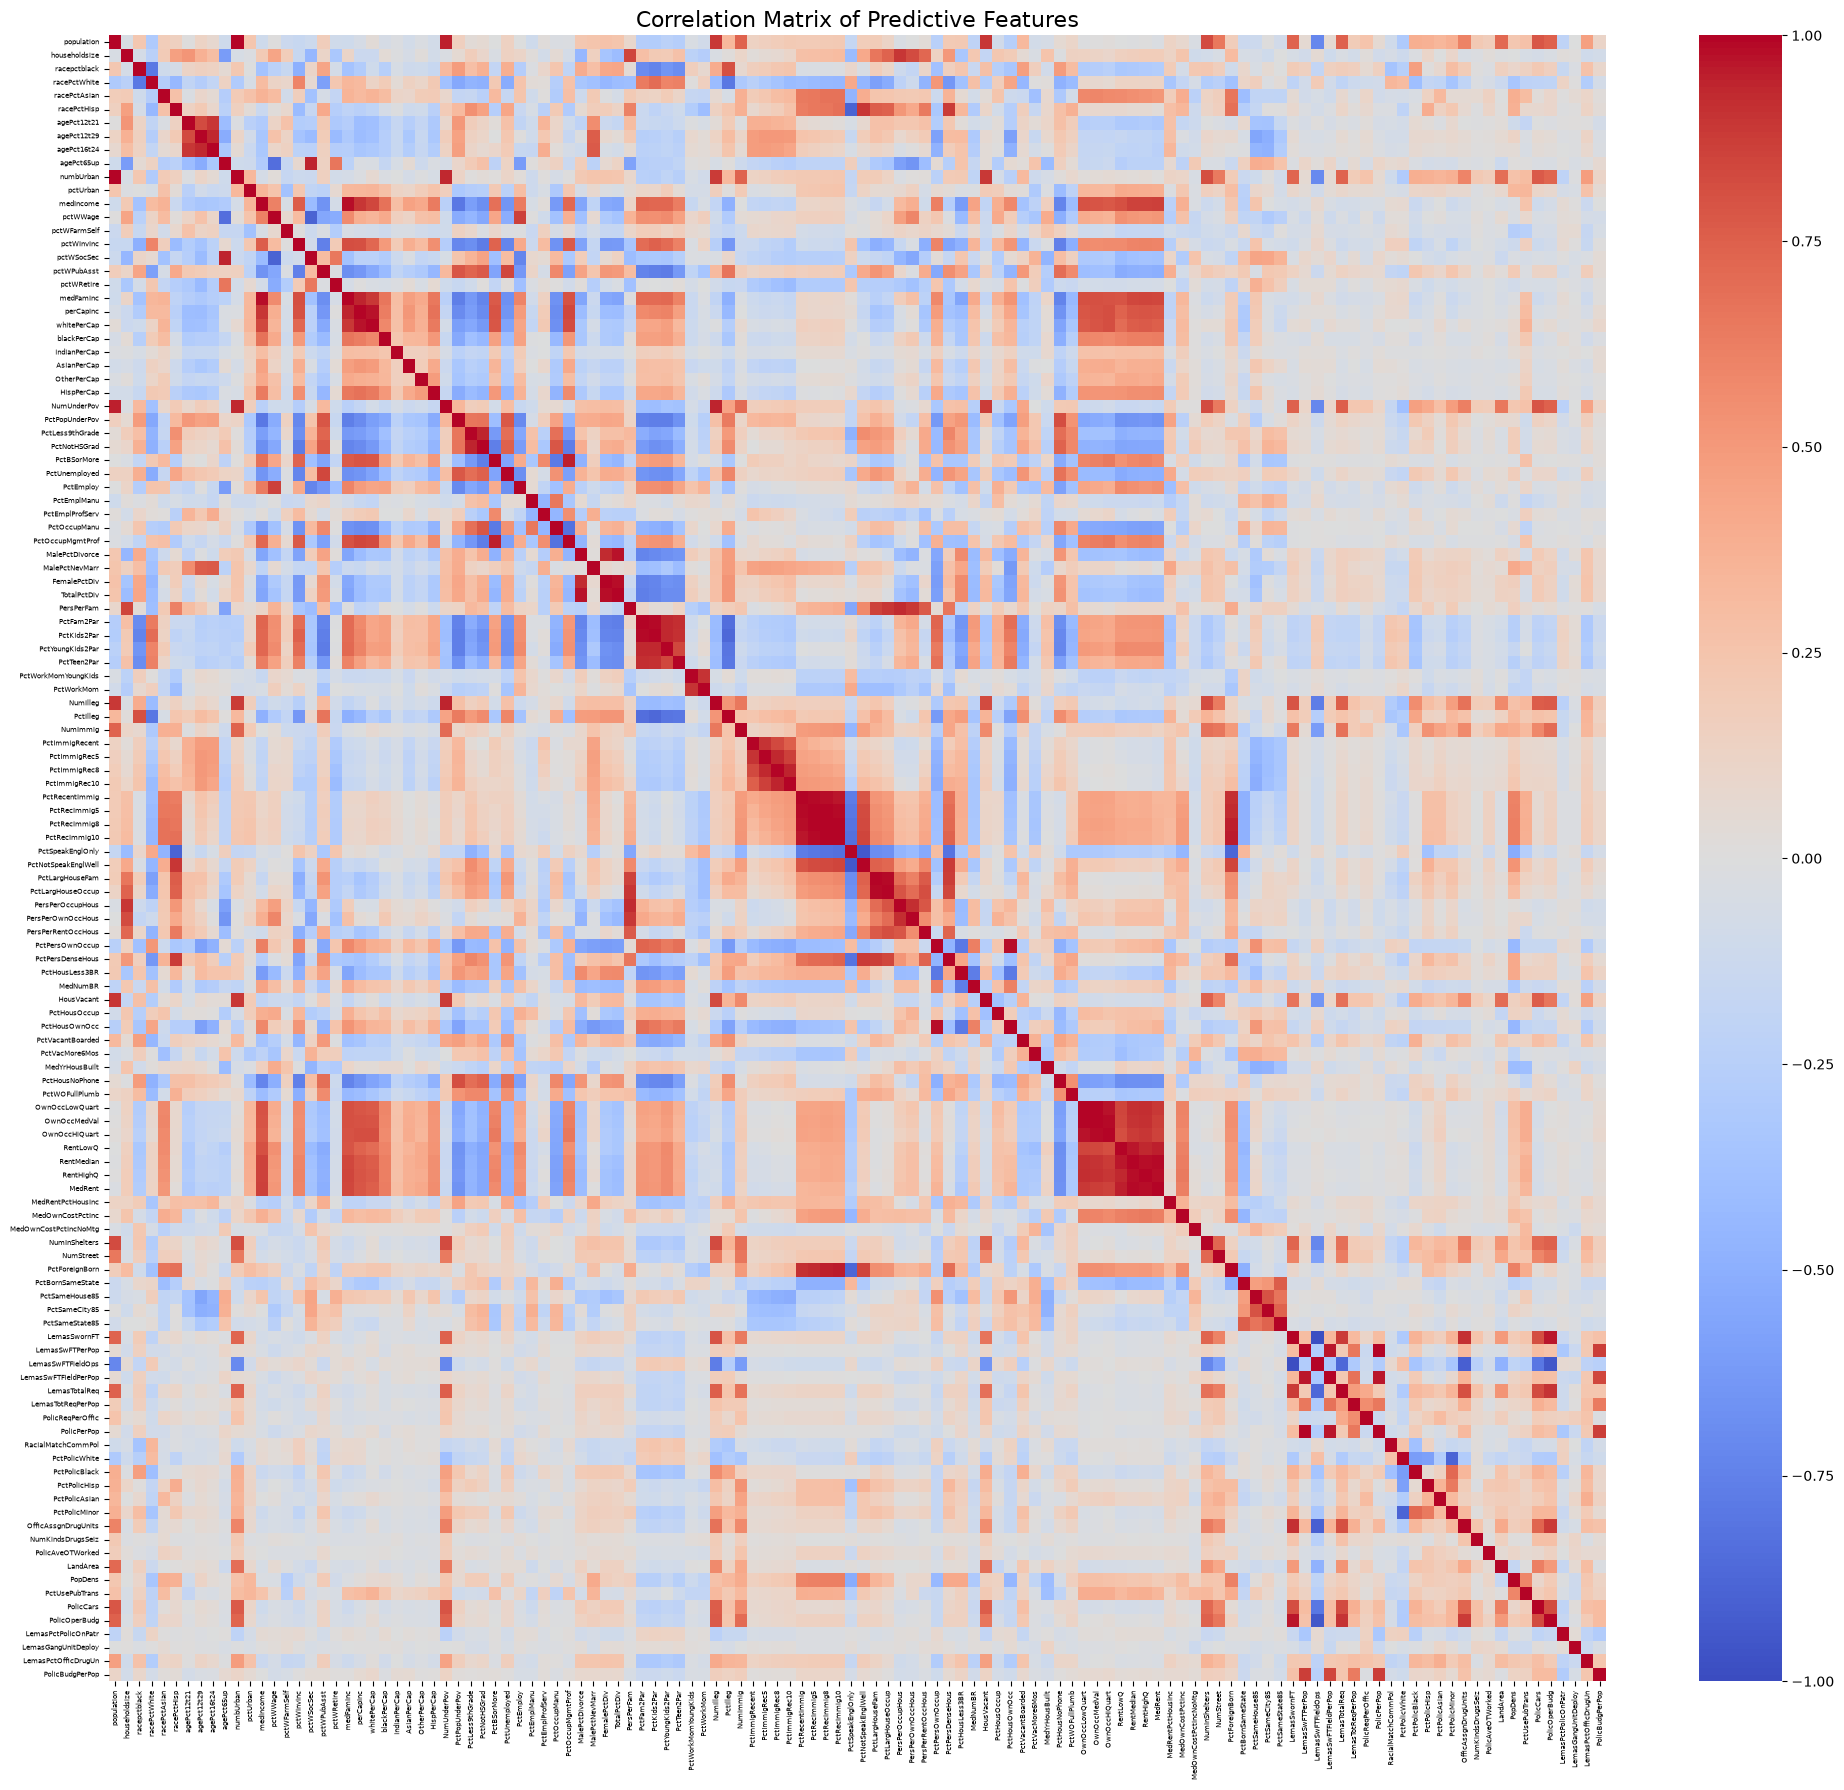

In [24]:
correlation_matrix = X_all_imputed.corr()

plt.figure(figsize=(20, 18))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=True,
    yticklabels=True
)

plt.title("Correlation Matrix of Predictive Features", fontsize=16)

plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.tight_layout()
plt.show()

In [25]:
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

strongest_correlations = (
    upper_triangle
    .stack()
    .sort_values(key=abs, ascending=False)
    .head(10)
)

print("Ten strongest feature correlations:")
print(strongest_correlations)

Ten strongest feature correlations:
LemasSwFTPerPop  PolicPerPop          0.999994
PctRecImmig8     PctRecImmig10        0.995525
OwnOccLowQuart   OwnOccMedVal         0.994481
PctRecImmig5     PctRecImmig8         0.993433
population       numbUrban            0.993112
LemasSwornFT     LemasSwFTFieldOps   -0.991590
OwnOccMedVal     OwnOccHiQuart        0.991302
PctRecentImmig   PctRecImmig5         0.988999
RentMedian       MedRent              0.988585
PctRecImmig5     PctRecImmig10        0.985616
dtype: float64


## (d)

In [26]:
feature_means = X_all_imputed.mean()

feature_standard_deviations = X_all_imputed.std(ddof=1)

cv_values = (feature_standard_deviations / feature_means)

cv_values = cv_values.replace([np.inf, -np.inf], np.nan)

In [27]:
cv_results = pd.DataFrame({
    "Mean": feature_means,
    "Sample_Standard_Deviation":
        feature_standard_deviations,
    "CV": cv_values
})

cv_results = cv_results.sort_values(by="CV", ascending=False)

cv_results

,Mean,Sample_Standard_Deviation,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
LemasPctOfficDrugUn,0.094052,0.240328,2.555266
NumUnderPov,0.055507,0.127941,2.304970
population,0.057593,0.126906,2.203503
LemasSwornFT,0.027944,0.058143,2.080712
numbUrban,0.064072,0.128256,2.001744


In [28]:
print("Features with the highest CV values:")
display(cv_results.head(15))

Features with the highest CV values:


,Mean,Sample_Standard_Deviation,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
LemasPctOfficDrugUn,0.094052,0.240328,2.555266
NumUnderPov,0.055507,0.127941,2.304970
population,0.057593,0.126906,2.203503
LemasSwornFT,0.027944,0.058143,2.080712
numbUrban,0.064072,0.128256,2.001744


## (e)

In [29]:
number_of_selected_features = int(np.floor(np.sqrt(128)))

selected_features = (
    cv_results["CV"]
    .dropna()
    .head(number_of_selected_features)
    .index
    .tolist()
)

print("Number of selected features:", number_of_selected_features)

print("\nSelected features:")
for number, feature in enumerate(selected_features, start=1):
    print(f"{number}. {feature}")

selected_cv_results = cv_results.loc[selected_features]

selected_cv_results

Number of selected features: 11

Selected features:
1. PctPolicAsian
2. NumStreet
3. NumInShelters
4. NumIlleg
5. NumImmig
6. LemasPctOfficDrugUn
7. NumUnderPov
8. population
9. LemasSwornFT
10. numbUrban
11. HousVacant


,Mean,Sample_Standard_Deviation,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
LemasPctOfficDrugUn,0.094052,0.240328,2.555266
NumUnderPov,0.055507,0.127941,2.304970
population,0.057593,0.126906,2.203503
LemasSwornFT,0.027944,0.058143,2.080712
numbUrban,0.064072,0.128256,2.001744


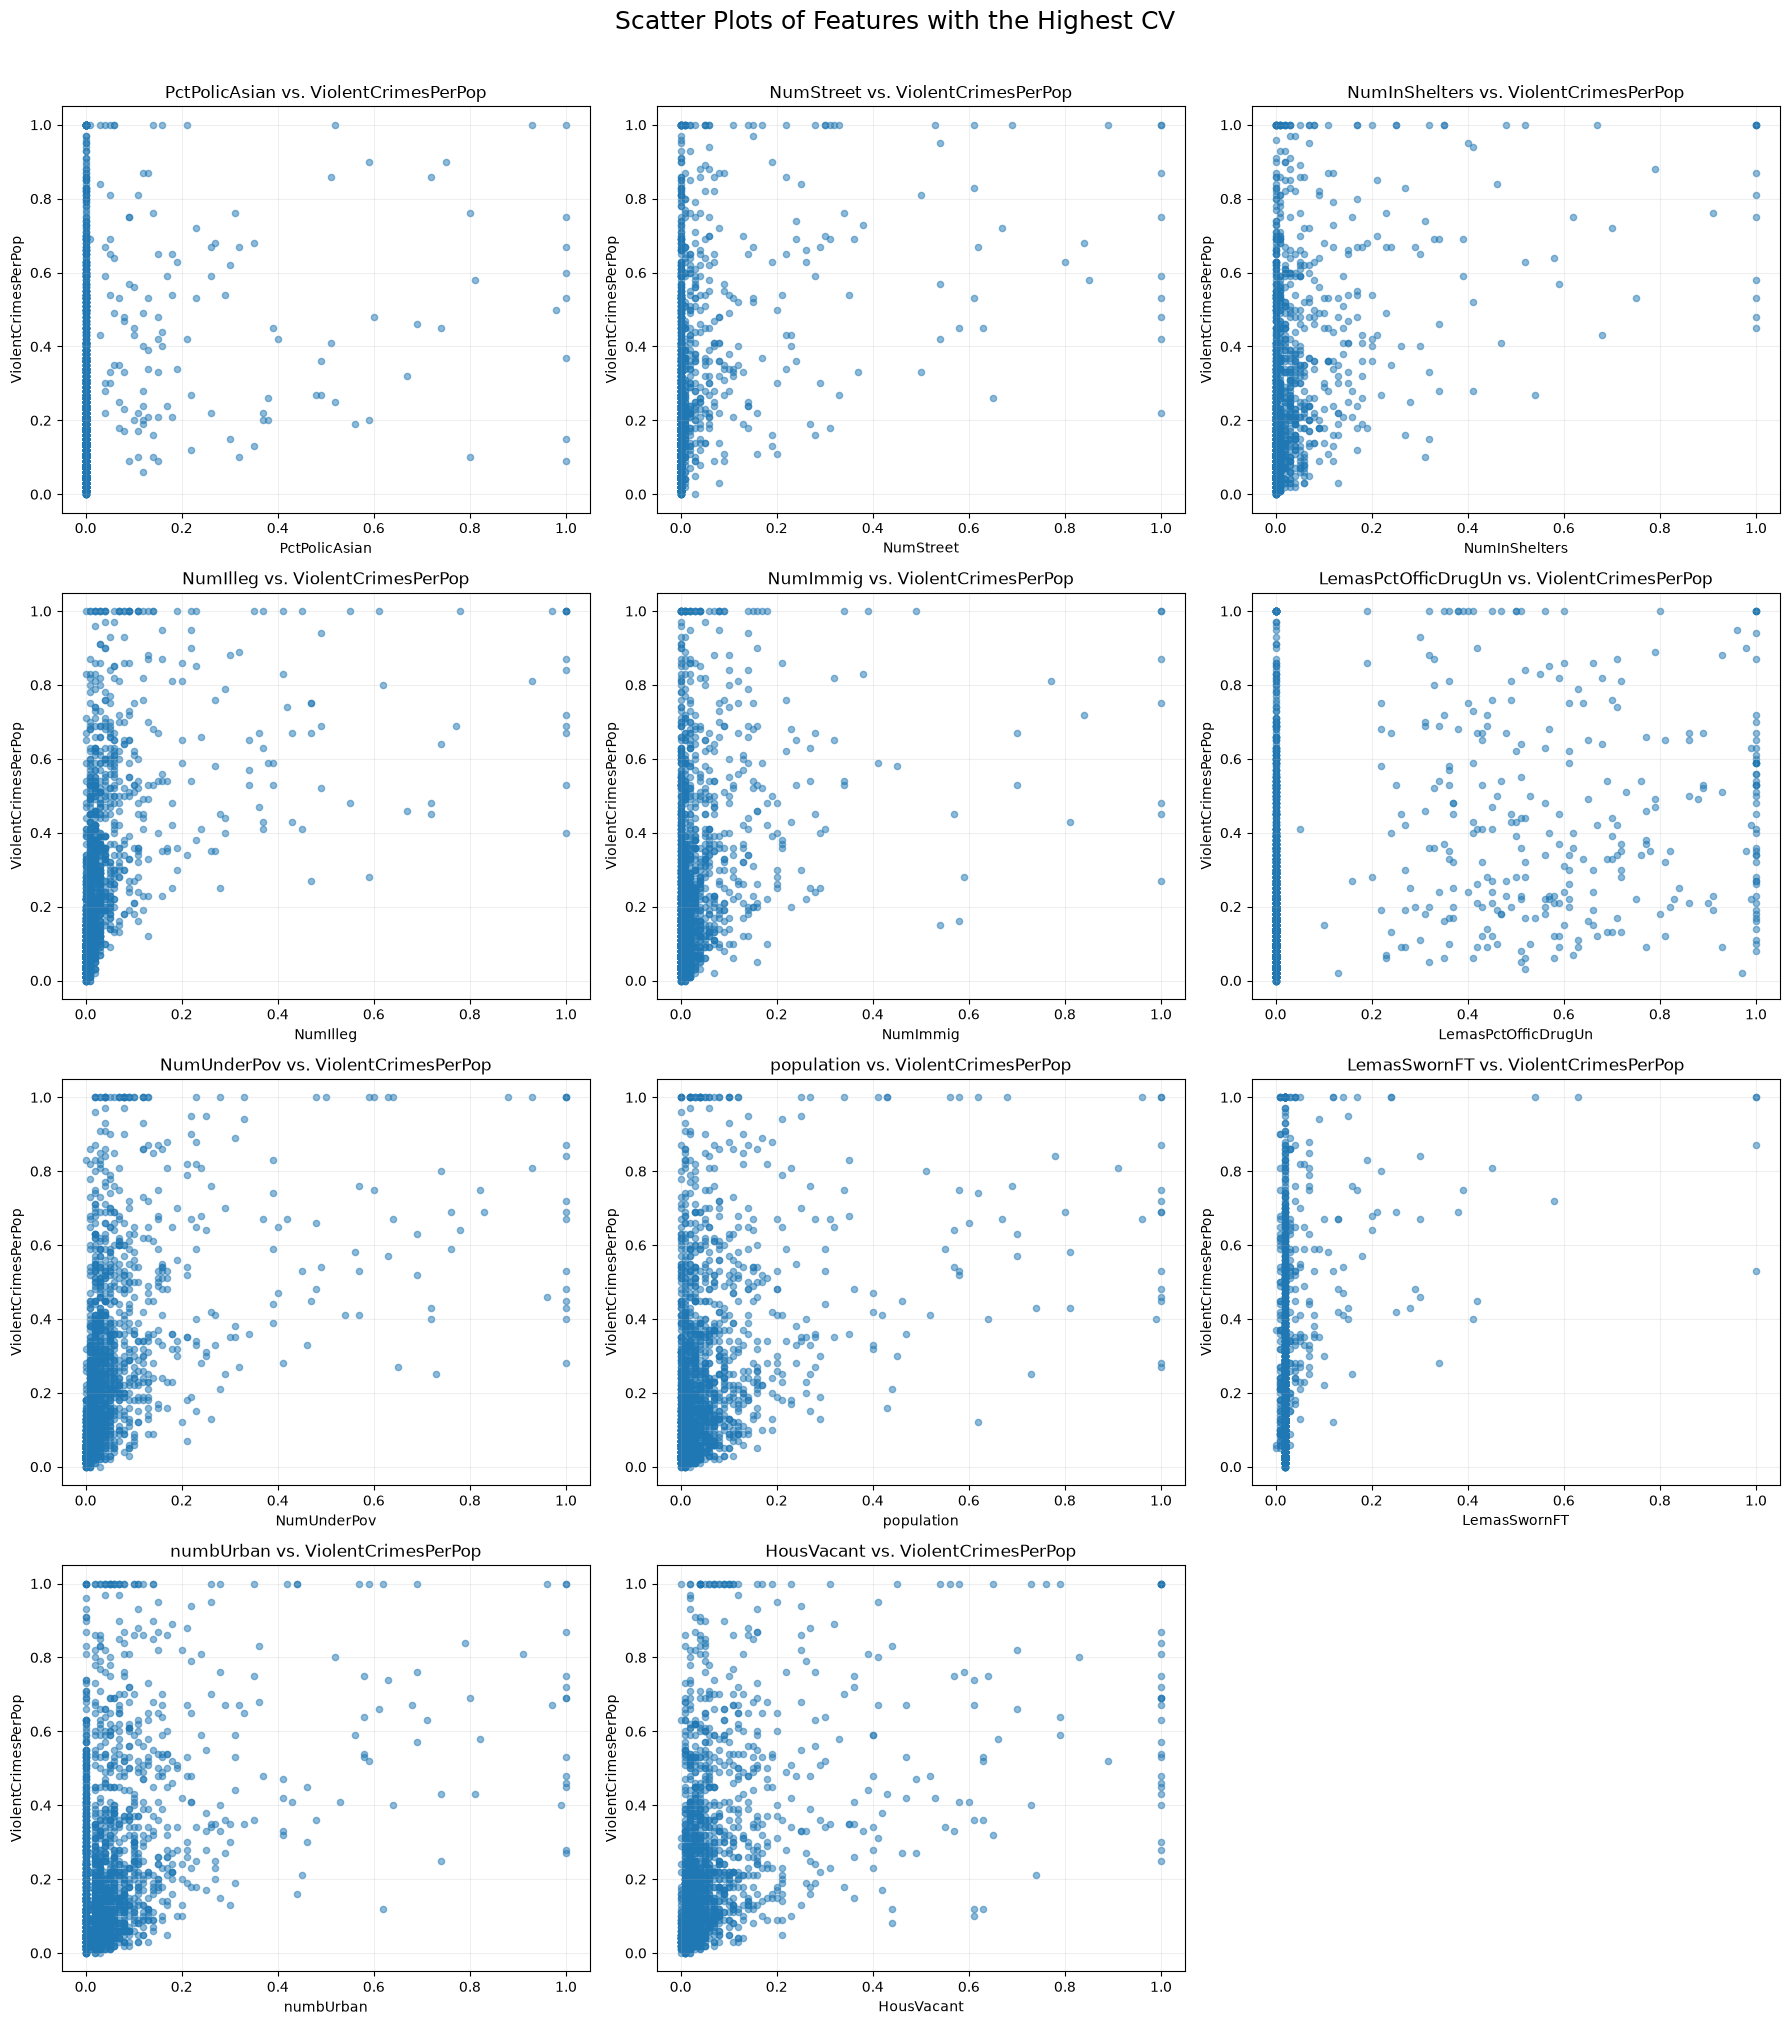

In [30]:
fig, axes = plt.subplots(4, 3, figsize=(18, 20))

axes = axes.flatten()

for index, feature in enumerate(selected_features):
    axes[index].scatter(X_all_imputed[feature], y_crime, alpha=0.5, s=20)

    axes[index].set_xlabel(feature)
    axes[index].set_ylabel("ViolentCrimesPerPop")
    axes[index].set_title(f"{feature} vs. ViolentCrimesPerPop")
    axes[index].grid(alpha=0.2)

for index in range(len(selected_features), len(axes)):
    axes[index].axis("off")

plt.suptitle("Scatter Plots of Features with the Highest CV", fontsize=18, y=1.01)

plt.tight_layout()
plt.show()

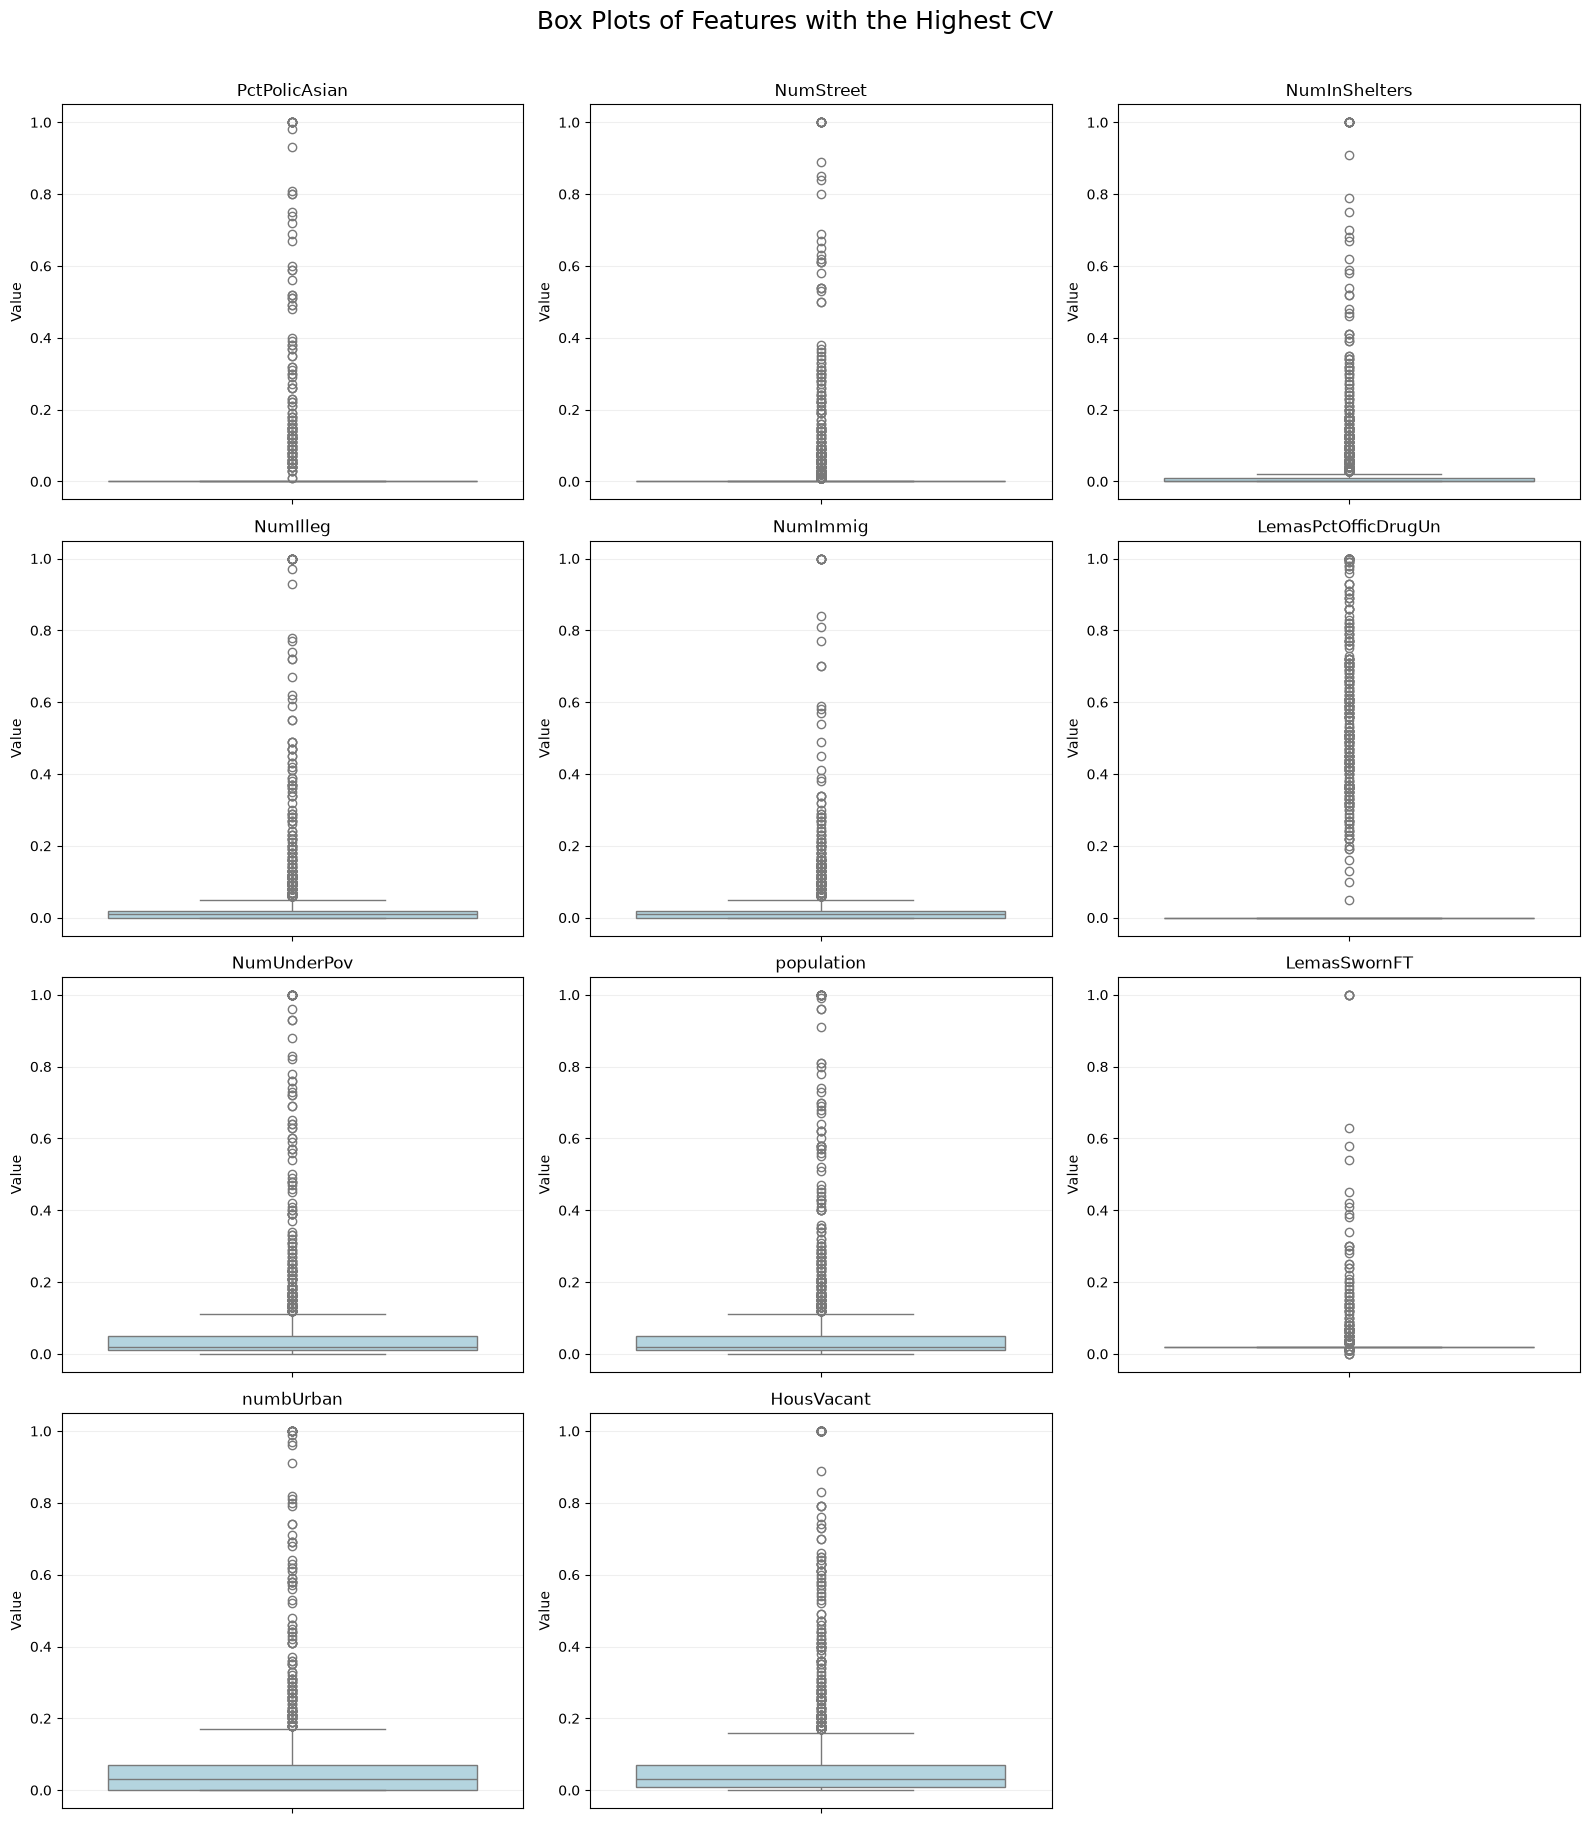

In [31]:
fig, axes = plt.subplots(4, 3, figsize=(16, 18))

axes = axes.flatten()

for index, feature in enumerate(selected_features):
    sns.boxplot(y=X_all_imputed[feature], ax=axes[index], color="lightblue")

    axes[index].set_title(feature)
    axes[index].set_ylabel("Value")
    axes[index].grid(axis="y", alpha=0.2)

for index in range(len(selected_features), len(axes)):
    axes[index].axis("off")

plt.suptitle("Box Plots of Features with the Highest CV", fontsize=18, y=1.01)

plt.tight_layout()
plt.show()

No. Scatter plots alone are not enough to determine statistical significance. They do not account for interactions, multicollinearity, or the effects of other predictors.

## (f)

In [32]:
ols_model = LinearRegression()

ols_model.fit(X_train_imputed, y_train)

ols_test_predictions = ols_model.predict(X_test_imputed)

ols_test_mse = mean_squared_error(y_test, ols_test_predictions)

print(f"OLS test MSE: {ols_test_mse:.6f}")

OLS test MSE: 0.017966


## (g)

In [33]:
ridge_alphas = np.logspace(-4, 4, 200)

ridge_cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [34]:
ridge_model = RidgeCV(
    alphas=ridge_alphas,
    cv=ridge_cv,
    scoring="neg_mean_squared_error"
)

ridge_model.fit(X_train_imputed, y_train)

print(f"Selected lambda: {ridge_model.alpha_:.6f}")

Selected lambda: 3.489101


In [35]:
ridge_test_predictions = ridge_model.predict(X_test_imputed)

ridge_test_mse = mean_squared_error(y_test, ridge_test_predictions)

print(f"Ridge test MSE: {ridge_test_mse:.6f}")

Ridge test MSE: 0.017468


## (h)

In [36]:
lasso_alphas = np.logspace(-5, 0, 200)

lasso_cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [37]:
lasso_model = LassoCV(
    alphas=lasso_alphas,
    cv=lasso_cv,
    max_iter=100000,
    random_state=42
)

lasso_model.fit(X_train_imputed, y_train)

print(f"Selected lambda: {lasso_model.alpha_:.8f}")

Selected lambda: 0.00011357


In [38]:
lasso_test_predictions = lasso_model.predict(X_test_imputed)

lasso_test_mse = mean_squared_error(y_test, lasso_test_predictions)

print(f"LASSO test MSE: {lasso_test_mse:.6f}")

LASSO test MSE: 0.017639


In [39]:
lasso_coefficients = pd.Series(lasso_model.coef_, index=X_train_imputed.columns)

lasso_selected_variables = lasso_coefficients[
    np.abs(lasso_coefficients) > 1e-8
].sort_values(key=abs, ascending=False)

print("Number of variables selected:", len(lasso_selected_variables))

print("\nSelected variables and coefficients:")
display(lasso_selected_variables.to_frame(name="Coefficient")
)

Number of variables selected: 73

Selected variables and coefficients:


,Coefficient
agePct12t29,-0.268749
racepctblack,0.268158
PctPersDenseHous,0.216009
PctKids2Par,-0.198386
MedRent,0.162754
RentLowQ,-0.159838
NumStreet,0.157878
PctPopUnderPov,-0.141246
PctEmploy,0.140844
MalePctNevMarr,0.136033


In [40]:
scaler = StandardScaler()

X_train_standardized = pd.DataFrame(
    scaler.fit_transform(X_train_imputed),
    columns=X_train_imputed.columns,
    index=X_train_imputed.index
)

X_test_standardized = pd.DataFrame(
    scaler.transform(X_test_imputed),
    columns=X_test_imputed.columns,
    index=X_test_imputed.index
)

In [41]:
standardized_lasso_model = LassoCV(
    alphas=lasso_alphas,
    cv=lasso_cv,
    max_iter=100000,
    random_state=42
)

standardized_lasso_model.fit(X_train_standardized, y_train)

print(
    "Selected lambda after standardization:",
    f"{standardized_lasso_model.alpha_:.8f}"
)

Selected lambda after standardization: 0.00060802


In [42]:
standardized_lasso_predictions = (standardized_lasso_model.predict(X_test_standardized)
)

standardized_lasso_test_mse = (
    mean_squared_error(y_test, standardized_lasso_predictions)
)

print("Standardized LASSO test MSE:", f"{standardized_lasso_test_mse:.6f}")

Standardized LASSO test MSE: 0.017731


In [43]:
standardized_lasso_coefficients = pd.Series(
    standardized_lasso_model.coef_,
    index=X_train_standardized.columns
)

standardized_lasso_selected_variables = (
    standardized_lasso_coefficients[np.abs(standardized_lasso_coefficients) > 1e-8
    ]
    .sort_values(key=abs, ascending=False)
)

print("Number of variables selected:", len(standardized_lasso_selected_variables))

print("\nSelected variables and coefficients:")
display(standardized_lasso_selected_variables.to_frame(name="Standardized_Coefficient")
)

Number of variables selected: 75

Selected variables and coefficients:


,Standardized_Coefficient
racepctblack,0.068132
agePct12t29,-0.044207
PctPersDenseHous,0.043917
PctKids2Par,-0.040581
RentLowQ,-0.031374
MedRent,0.031256
PctPopUnderPov,-0.029911
PctEmploy,0.025800
MalePctNevMarr,0.025499
PctIlleg,0.023748


In [44]:
lasso_comparison = pd.DataFrame({
    "Model": [
        "LASSO without additional standardization",
        "LASSO with standardized features"
    ],
    "Selected_Lambda": [lasso_model.alpha_, standardized_lasso_model.alpha_],
    "Number_of_Selected_Variables": [
        len(lasso_selected_variables),
        len(standardized_lasso_selected_variables)
    ],
    "Test_MSE": [lasso_test_mse, standardized_lasso_test_mse]
})

lasso_comparison

,Model,Selected_Lambda,Number_of_Selected_Variables,Test_MSE
0,LASSO without additional standardization,0.000114,73,0.017639
1,LASSO with standardized features,0.000608,75,0.017731


## (i)

In [45]:
from sklearn.model_selection import GridSearchCV

In [46]:
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("linear_regression", LinearRegression())
])

In [47]:
pcr_parameter_grid = {"pca__n_components": range(1, X_train_imputed.shape[1] + 1)
}

pcr_cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [48]:
pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid=pcr_parameter_grid,
    scoring="neg_mean_squared_error",
    cv=pcr_cv,
    n_jobs=-1
)

pcr_search.fit(X_train_imputed, y_train)

best_M = pcr_search.best_params_["pca__n_components"]

print("Selected number of principal components:", best_M)

Selected number of principal components: 60


In [49]:
best_pcr_model = pcr_search.best_estimator_

pcr_test_predictions = best_pcr_model.predict(X_test_imputed)

pcr_test_mse = mean_squared_error(y_test, pcr_test_predictions)

print("Selected M:", best_M)

print(f"PCR test MSE: {pcr_test_mse:.6f}")

Selected M: 60
PCR test MSE: 0.018350


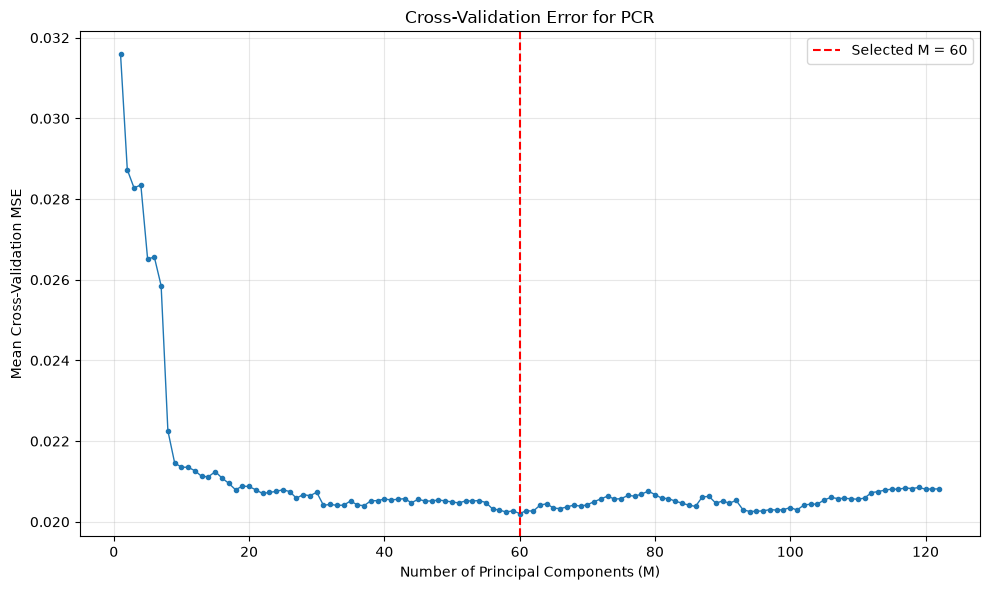

In [50]:
pcr_results = pd.DataFrame(pcr_search.cv_results_)

component_numbers = (pcr_results["param_pca__n_components"].astype(int)
)

pcr_cv_mse = (-pcr_results["mean_test_score"])

plt.figure(figsize=(10, 6))

plt.plot(component_numbers, pcr_cv_mse, marker="o", markersize=3, linewidth=1)

plt.axvline(best_M, color="red", linestyle="--", label=f"Selected M = {best_M}")

plt.xlabel("Number of Principal Components (M)")

plt.ylabel("Mean Cross-Validation MSE")

plt.title("Cross-Validation Error for PCR")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
selected_pca = best_pcr_model.named_steps["pca"]

explained_variance = (selected_pca.explained_variance_ratio_.sum())

print("Cumulative explained variance:", f"{explained_variance:.4f}")

Cumulative explained variance: 0.9806
